In [1]:
import pandas as pd
import numpy as np
import seaborn as sn
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings("ignore",category=FutureWarning)
import plotly.express as px
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix

In [2]:
data = pd.read_csv("breast-cancer.csv")
data.head()

,S/N,Year,Age,Menopause,Tumor Size (cm),Inv-Nodes,Breast,Metastasis,Breast Quadrant,History,Diagnosis Result
0,1,2019,40,1,2,0,Right,0,Upper inner,0,Benign
1,2,2019,39,1,2,0,Left,0,Upper outer,0,Benign
2,3,2019,45,0,4,0,Left,0,Lower outer,0,Benign
3,4,2019,26,1,3,0,Left,0,Lower inner,1,Benign
4,5,2019,21,1,1,0,Right,0,Upper outer,1,Benign


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 213 entries, 0 to 212
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   S/N               213 non-null    int64 
 1   Year              213 non-null    object
 2   Age               213 non-null    int64 
 3   Menopause         213 non-null    int64 
 4   Tumor Size (cm)   213 non-null    object
 5   Inv-Nodes         213 non-null    object
 6   Breast            213 non-null    object
 7   Metastasis        213 non-null    object
 8   Breast Quadrant   213 non-null    object
 9   History           213 non-null    object
 10  Diagnosis Result  213 non-null    object
dtypes: int64(3), object(8)
memory usage: 18.4+ KB


In [4]:
data.describe(include = 'all')

,S/N,Year,Age,Menopause,Tumor Size (cm),Inv-Nodes,Breast,Metastasis,Breast Quadrant,History,Diagnosis Result
count,213.000000,213,213.000000,213.000000,213,213,213,213,213,213,213
unique,NaN,3,NaN,NaN,13,4,3,3,6,3,2
top,NaN,2020,NaN,NaN,3,0,Left,0,Upper outer,0,Benign
freq,NaN,111,NaN,NaN,34,139,107,139,67,124,120
mean,107.000000,NaN,39.784038,0.666667,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,61.631972,NaN,14.096712,0.472515,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,13.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,54.000000,NaN,30.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,107.000000,NaN,40.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,160.000000,NaN,49.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
data.tail()

,S/N,Year,Age,Menopause,Tumor Size (cm),Inv-Nodes,Breast,Metastasis,Breast Quadrant,History,Diagnosis Result
208,209,2020,49,1,6,3,Right,1,Lower inner,1,Malignant
209,210,2020,28,1,3,0,Left,0,Upper inner,0,Benign
210,211,2020,22,1,1,0,Left,0,Upper outer,1,Benign
211,212,2020,19,1,1,0,Left,0,Lower inner,1,Benign
212,213,2020,50,0,4,0,Right,0,Lower outer,1,Benign


In [6]:
data = data.dropna()

In [7]:
data['Diagnosis Result'].unique()

array(['Benign', 'Malignant'], dtype=object)

In [8]:
data['Breast'].unique()

array(['Right', 'Left', '#'], dtype=object)

In [9]:
data['Breast'] = data['Breast'].replace('#',np.nan)

In [10]:
data['Tumor Size (cm)'].unique()

array(['2', '4', '3', '1', '5', '6', '7', '10', '8', '9', '#', '14', '12'],
      dtype=object)

In [11]:
data['Tumor Size (cm)'] = data['Tumor Size (cm)'].replace('#',np.nan)

In [12]:
data = data.dropna()

In [13]:
data['Tumor Size (cm)'] = data['Tumor Size (cm)'].astype(int)
data['Inv-Nodes'] = data['Inv-Nodes'].astype(int)
data['Metastasis'] = data['Metastasis'].astype(int)
data['Breast Quadrant'] = data['Breast Quadrant'].astype(str)


In [14]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 207 entries, 0 to 212
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   S/N               207 non-null    int64 
 1   Year              207 non-null    object
 2   Age               207 non-null    int64 
 3   Menopause         207 non-null    int64 
 4   Tumor Size (cm)   207 non-null    int32 
 5   Inv-Nodes         207 non-null    int32 
 6   Breast            207 non-null    object
 7   Metastasis        207 non-null    int32 
 8   Breast Quadrant   207 non-null    object
 9   History           207 non-null    object
 10  Diagnosis Result  207 non-null    object
dtypes: int32(3), int64(3), object(5)
memory usage: 17.0+ KB


In [15]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
data['Breast'] = le.fit_transform(data['Breast'])

In [16]:
data.head()

,S/N,Year,Age,Menopause,Tumor Size (cm),Inv-Nodes,Breast,Metastasis,Breast Quadrant,History,Diagnosis Result
0,1,2019,40,1,2,0,1,0,Upper inner,0,Benign
1,2,2019,39,1,2,0,0,0,Upper outer,0,Benign
2,3,2019,45,0,4,0,0,0,Lower outer,0,Benign
3,4,2019,26,1,3,0,0,0,Lower inner,1,Benign
4,5,2019,21,1,1,0,1,0,Upper outer,1,Benign


In [17]:
data.shape

(207, 11)

In [18]:
#identing missing values and duplicate values
duplicates =data[data.duplicated()]
print(duplicates)

missing_values = data.isnull().sum()
print(missing_values)

Empty DataFrame
Columns: [S/N, Year, Age, Menopause, Tumor Size (cm), Inv-Nodes, Breast, Metastasis, Breast Quadrant, History, Diagnosis Result]
Index: []
S/N                 0
Year                0
Age                 0
Menopause           0
Tumor Size (cm)     0
Inv-Nodes           0
Breast              0
Metastasis          0
Breast Quadrant     0
History             0
Diagnosis Result    0
dtype: int64


In [19]:
X = data.drop('Diagnosis Result', axis=1)  # Replace 'target_column_name' with the actual name of your target column
y = data['Diagnosis Result']


In [20]:
#Split data 
X_train,X_test,y_train,y_test= train_test_split(X,y,test_size=0.2,random_state=42)

In [21]:
len(X_train)

165

In [22]:
len(X_test)

42

In [23]:
X_test.shape

(42, 10)

In [24]:
X_train.shape

(165, 10)

In [25]:
#import pandas as pd
#from sklearn.preprocessing import LabelEncoder

# Load your breast cancer dataset (replace 'your_data.csv' with your actual file path)
#data = pd.read_csv('your_data.csv')

# Check if the column exists and is of object type (categorical)
#if 'Diagnosis Result' in data.columns and data['Diagnosis Result'].dtype == 'object':
    # Handle potential missing values
    #data['Diagnosis Result'].fillna('unknown', inplace=True)

    # Encode categorical values using LabelEncoder
   # le = LabelEncoder()
    #data['Diagnosis Result_numeric'] = le.fit_transform(data['Diagnosis Result'])


    # Drop the original categorical column (optional)
#data.drop('Diagnosis Result', axis=1, inplace=True)

# Now you have a new column 'diagnose_result_numeric' with numeric values

In [26]:
#import pandas as pd
#from sklearn.preprocessing import LabelEncoder

# Load your breast cancer dataset (replace 'your_data.csv' with your actual file path)
#data = pd.read_csv('your_data.csv')

# Check if the column exists and is of object type (categorical)
#if 'Breast' in data.columns and data['Breast'].dtype == 'object':
    # Handle potential missing values
    #data['Breast'].fillna('unknown', inplace=True)

    # Encode categorical values using LabelEncoder
    #le = LabelEncoder()
    #data['Breast'] = le.fit_transform(data['Breast'])


    # Drop the original categorical column (optional)
    #data.drop('Breast', axis=1, inplace=True)

# Now you have a new column 'diagnose_result_numeric' with numeric values

In [27]:
#data.head()

In [28]:
#import pandas as pd
#from sklearn.preprocessing import LabelEncoder

# Load your breast cancer dataset (replace 'your_data.csv' with your actual file path)
#data = pd.read_csv('your_data.csv')

# Check if the column exists and is of object type (categorical)
#if 'Breast Quadrant' in data.columns and data['Breast Quadrant'].dtype == 'object':
    # Handle potential missing values
    #data['Breast Quadrant'].fillna('unknown', inplace=True)

    # Encode categorical values using LabelEncoder
   # le = LabelEncoder()
    #data['Breast Quadrant'] = le.fit_transform(data['Breast Quadrant'])


    # Drop the original categorical column (optional)
   # data.drop('Breast Quadrant', axis=1, inplace=True)

# Now you have a new column 'diagnose_result_numeric' with numeric values

In [29]:
#data.head()

In [30]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
data['Diagnosis Result'] = le.fit_transform(data['Diagnosis Result'])

scaler = StandardScaler()
data['Diagnosis Result'] = scaler.fit_transform(data['Diagnosis Result'].values.reshape(-1, 1))

In [31]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
data['Breast'] = le.fit_transform(data['Breast'])
data['Diagnosis Result'] = le.fit_transform(data['Diagnosis Result'])

In [32]:
print(data.columns)

Index(['S/N', 'Year', 'Age', 'Menopause', 'Tumor Size (cm)', 'Inv-Nodes',
       'Breast', 'Metastasis', 'Breast Quadrant', 'History',
       'Diagnosis Result'],
      dtype='object')


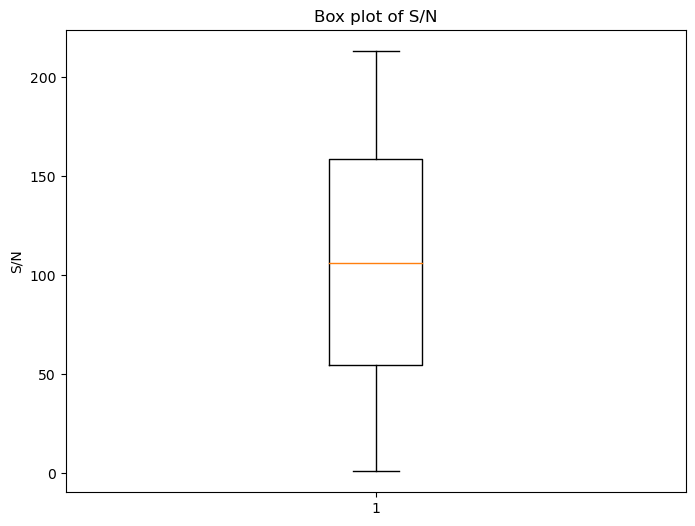

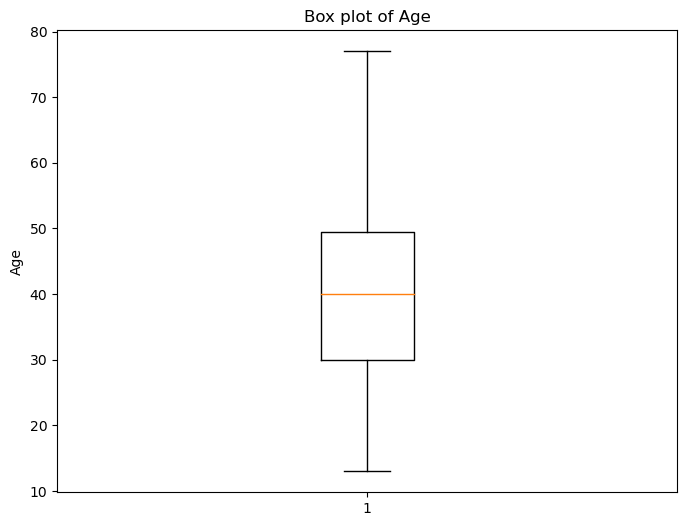

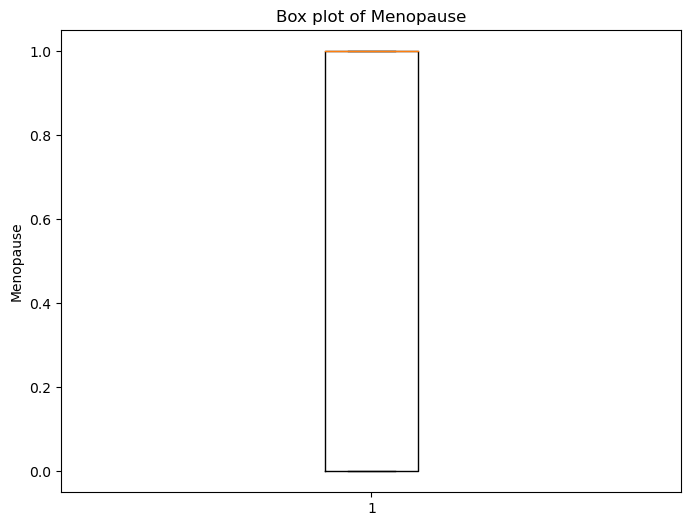

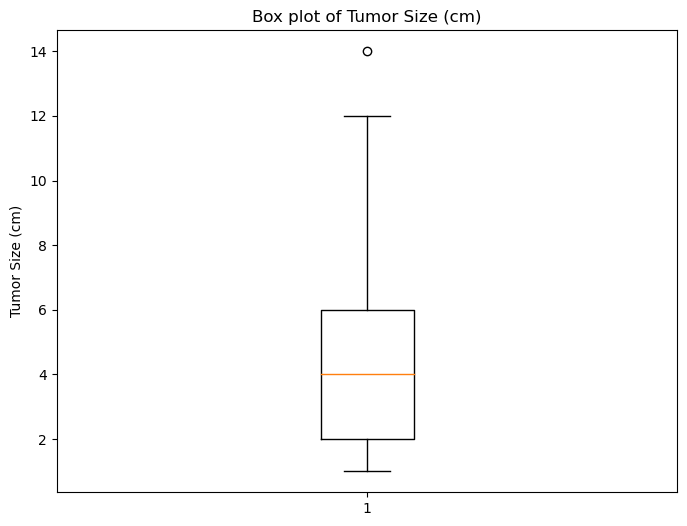

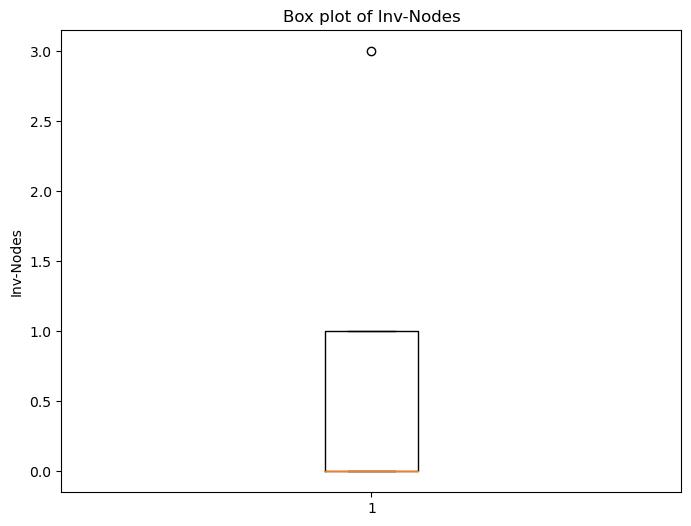

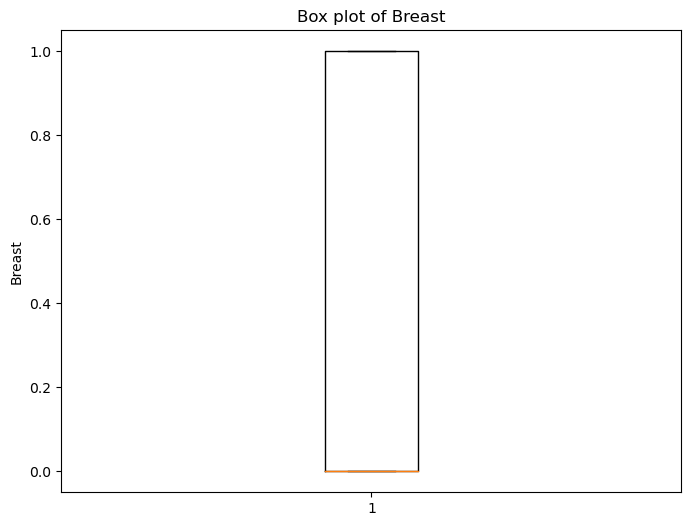

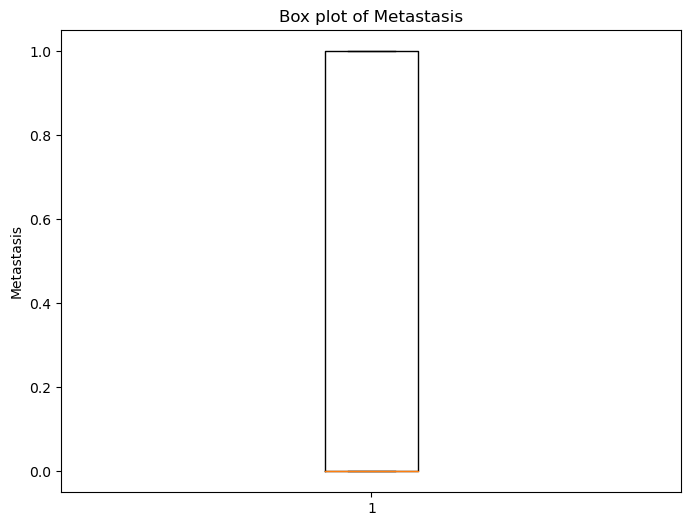

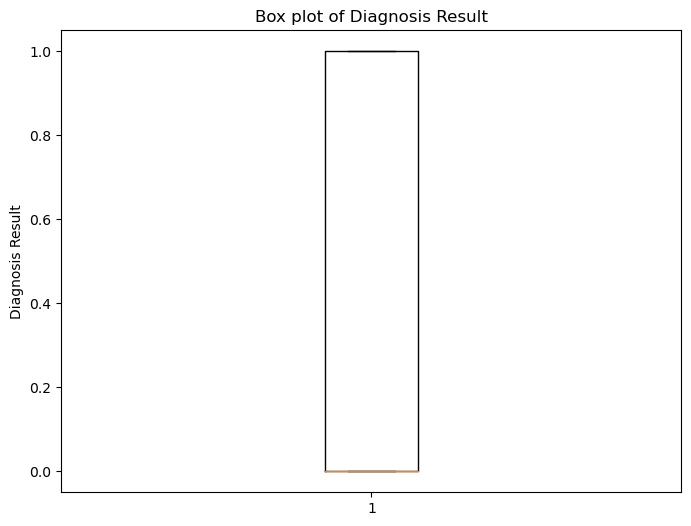

In [33]:
for column in data.select_dtypes(include=np.number).columns:
    plt.figure(figsize=(8,6))
    plt.boxplot(data[column])
    plt.title(f'Box plot of {column}')
    plt.ylabel(column)
    plt.show()

In [34]:
Q1 = data['Tumor Size (cm)'].quantile(0.25)
Q3 = data['Tumor Size (cm)'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

data = data[
    (data['Tumor Size (cm)'] >= lower_bound)  &  (data['Tumor Size (cm)'] <= upper_bound)
]


In [35]:
Q1 = data['Inv-Nodes'].quantile(0.25)
Q3 = data['Inv-Nodes'].quantile(0.25)
IQR =Q3 -Q1

lower_bound = Q1 - 1.5 *IQR
upper_bound = Q3 + 1.5 * IQR

data = data[
    (data['Inv-Nodes'] >= lower_bound) &  (data['Inv-Nodes'] <= upper_bound)
]


In [36]:
data.head()

,S/N,Year,Age,Menopause,Tumor Size (cm),Inv-Nodes,Breast,Metastasis,Breast Quadrant,History,Diagnosis Result
0,1,2019,40,1,2,0,1,0,Upper inner,0,0
1,2,2019,39,1,2,0,0,0,Upper outer,0,0
2,3,2019,45,0,4,0,0,0,Lower outer,0,0
3,4,2019,26,1,3,0,0,0,Lower inner,1,0
4,5,2019,21,1,1,0,1,0,Upper outer,1,0


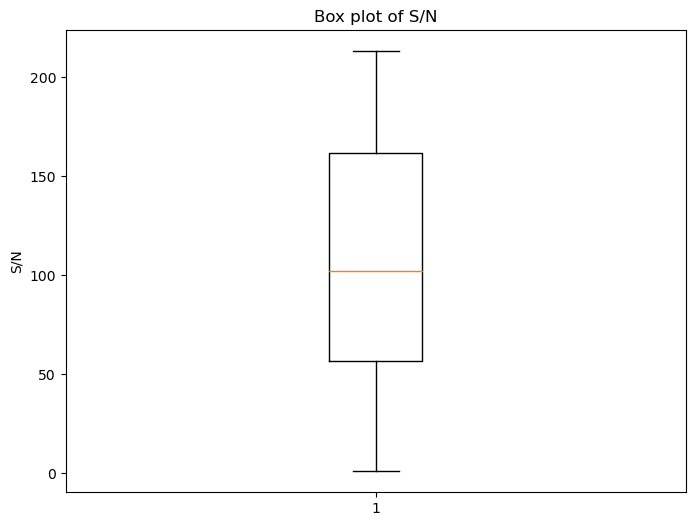

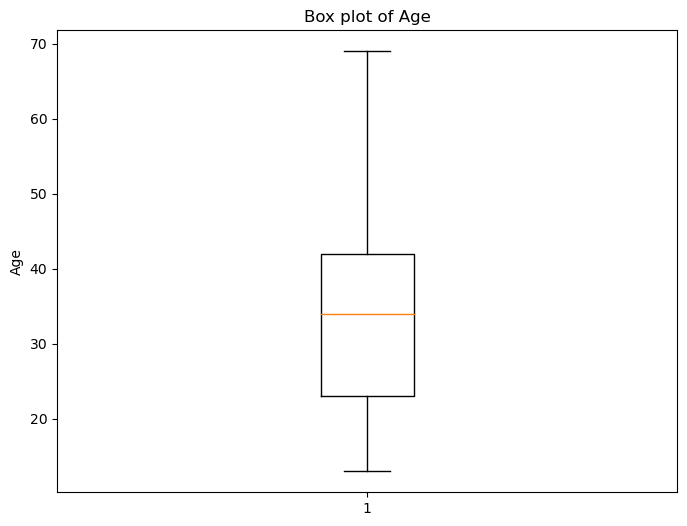

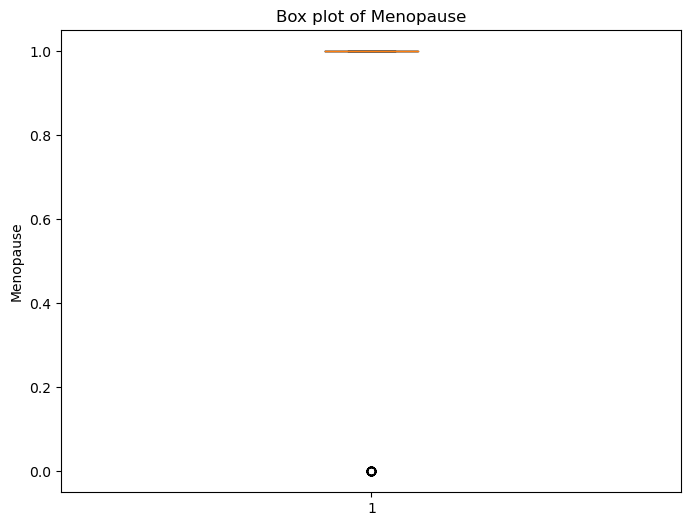

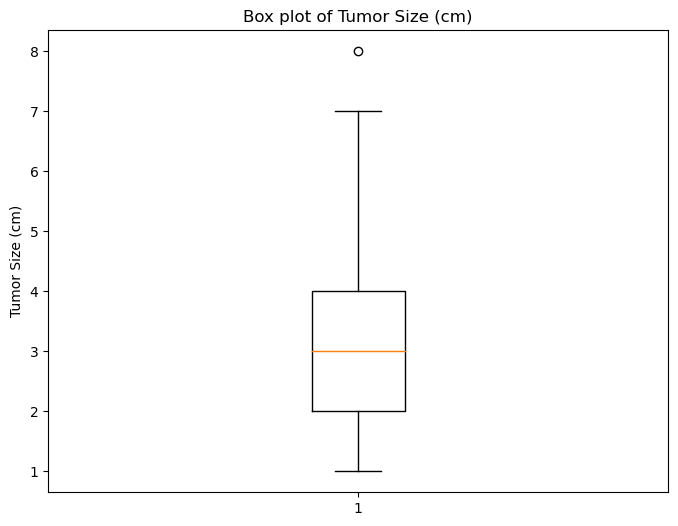

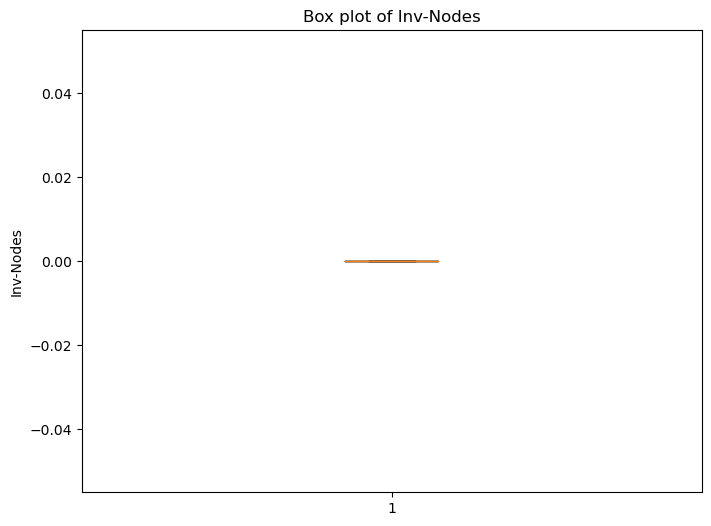

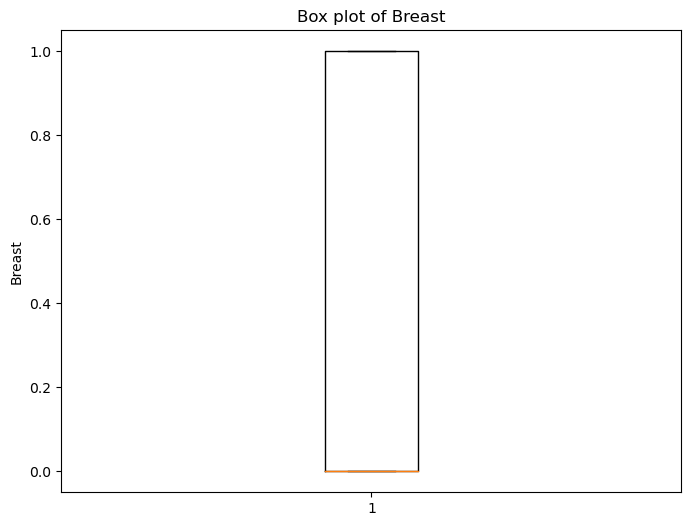

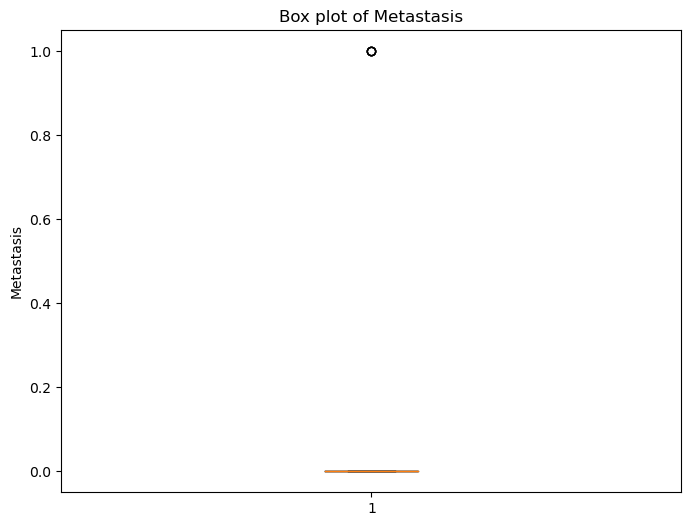

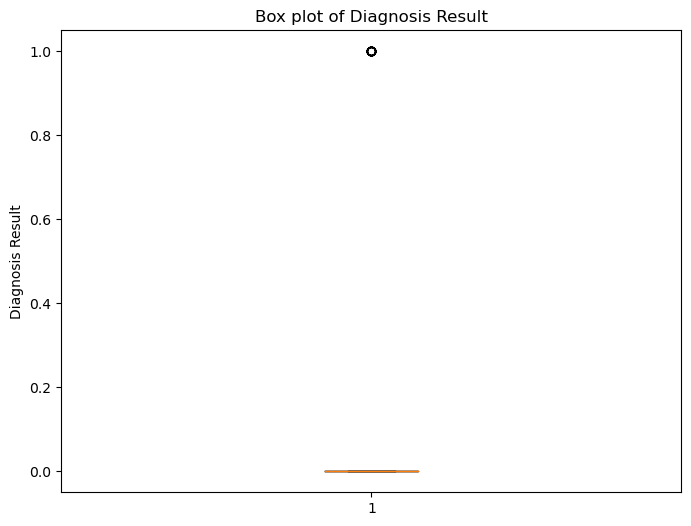

In [37]:
for column in data.select_dtypes(include=np.number).columns:
    plt.figure(figsize=(8,6))
    plt.boxplot(data[column])
    plt.title(f'Box plot of {column}')
    plt.ylabel(column)
    plt.show()

In [38]:
# Find rows with "Upper outer" (assuming it's in a column named 'column_name')
string_rows = X_train[X_train['Breast Quadrant'] == 'Upper outer']

# Check if any rows were found
if len(string_rows) > 0:
  # Option 1: Remove rows (if desired)
  X_train_removed = X_train.drop(string_rows.index)
print(X_train_removed.shape)


(111, 10)


In [39]:
# Find rows with specific values (assuming it's in a column named 'Breast Quadrant')
desired_values = ['Upper inner', 'Upper outer', 'Lower outer', 'Lower inner']
string_rows = X_train[X_train['Breast Quadrant'].isin(desired_values)]

# Check if any rows were found
if len(string_rows) > 0:
  # Option 1: Remove rows (if desired)
  X_train_removed = X_train.drop(string_rows.index)
else:
  # Handle the case where no rows contain desired values (optional)
  print("No rows found with 'Upper outer', 'Lower inner', 'Lower outer', or 'Upper inner'")
  # Consider alternative approaches (e.g., imputation)

# Check if X_train_removed is not empty before fitting
if X_train_removed.shape[0] > 0:
  model.fit(X_train_removed, y_train)
else:
  print("Not enough data to fit the model. Consider alternative approaches for handling missing values.")

Not enough data to fit the model. Consider alternative approaches for handling missing values.


In [40]:
print(X_train.shape)
print(y_train.shape)

(165, 10)
(165,)


In [41]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
data['Breast Quadrant'] = le.fit_transform(data['Breast Quadrant'])

In [42]:
data.head()

,S/N,Year,Age,Menopause,Tumor Size (cm),Inv-Nodes,Breast,Metastasis,Breast Quadrant,History,Diagnosis Result
0,1,2019,40,1,2,0,1,0,2,0,0
1,2,2019,39,1,2,0,0,0,3,0,0
2,3,2019,45,0,4,0,0,0,1,0,0
3,4,2019,26,1,3,0,0,0,0,1,0
4,5,2019,21,1,1,0,1,0,3,1,0


In [44]:
data.tail()

,S/N,Year,Age,Menopause,Tumor Size (cm),Inv-Nodes,Breast,Metastasis,Breast Quadrant,History,Diagnosis Result
205,206,2020,16,1,2,0,1,0,2,0,0
209,210,2020,28,1,3,0,0,0,2,0,0
210,211,2020,22,1,1,0,0,0,3,1,0
211,212,2020,19,1,1,0,0,0,0,1,0
212,213,2020,50,0,4,0,1,0,1,1,0


In [45]:
model = LogisticRegression()

In [46]:
model.fit(X_train,y_train)

ValueError: could not convert string to float: 'Upper outer'

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test,y_pred)
print("Confusion Matrix")
print(cm)

In [ ]:
accuracy = accuracy_score(y_test,y_pred)
print(f"Accuracy:{accuracy}")
print(classification_report(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))